In [1]:
import sqlite3
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean styling for all plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100

# 1. Connect to SQLite database (go one folder up if inside 'notebooks/')
import os
db_path = "kilimall_data.db" if os.path.exists("kilimall_data.db") else "../kilimall_data.db"

conn = sqlite3.connect(db_path)

# 2. Extract combined product details and daily observations
query = """
SELECT 
    p.product_id,
    p.name,
    p.category,
    p.product_url,
    o.observation_id,
    o.price,
    o.original_price,
    o.discount_percent,
    o.rating,
    o.units_sold,
    o.scraped_at
FROM observations o
JOIN products p ON o.product_id = p.product_id
ORDER BY o.scraped_at ASC;
"""

df = pd.read_sql_query(query, conn)
conn.close()

# 3. Clean dates and extract brand names
df["scraped_at"] = pd.to_datetime(df["scraped_at"])
df["scrape_date"] = df["scraped_at"].dt.strftime("%Y-%m-%d")

KNOWN_BRANDS = ["Samsung", "Apple", "Xiaomi", "Redmi", "Tecno", "Infinix", "Oppo", "Vivo", "Nokia", "Huawei", "Lenovo", "HP", "Dell", "Sony", "Oraimo", "JBL", "Zealot"]
def get_brand(name):
    for b in KNOWN_BRANDS:
        if re.search(r"\b" + b + r"\b", str(name), re.IGNORECASE):
            return b
    return "Other / Unbranded"

df["brand"] = df["name"].apply(get_brand)

print("Data Loaded Successfully!")
print(f"Total Rows Extracted: {len(df)}")
print(f"Observation Dates:    {list(df['scrape_date'].unique())}")
df.head(3)

Data Loaded Successfully!
Total Rows Extracted: 2487
Observation Dates:    ['2026-10-14', '2026-10-15', '2026-10-19']


,product_id,name,category,product_url,observation_id,price,original_price,discount_percent,rating,units_sold,scraped_at,scrape_date,brand
0,3054740,Brand New Samsung Galaxy A06 64GB+4GB 50MP Cam...,Phones & Accessories,https://www.kilimall.co.ke/listing/3054740-Sam...,1,13999.0,13999.0,0.0,4.0,3261,2026-10-14 12:46:55,2026-10-14,Samsung
1,1002092604,[Xiaomi Official] Brand New Redmi 15C 128GB + ...,Phones & Accessories,https://www.kilimall.co.ke/listing/1002092604-...,2,16499.0,16499.0,0.0,4.0,97,2026-10-14 12:46:55,2026-10-14,Xiaomi
2,2543007,Refurbished OPPO Reno 2z 128GB+8GB 6.5 inch 48...,Phones & Accessories,https://www.kilimall.co.ke/listing/2543007-Ref...,3,10999.0,10999.0,0.0,4.0,3175,2026-10-14 12:46:55,2026-10-14,Oppo


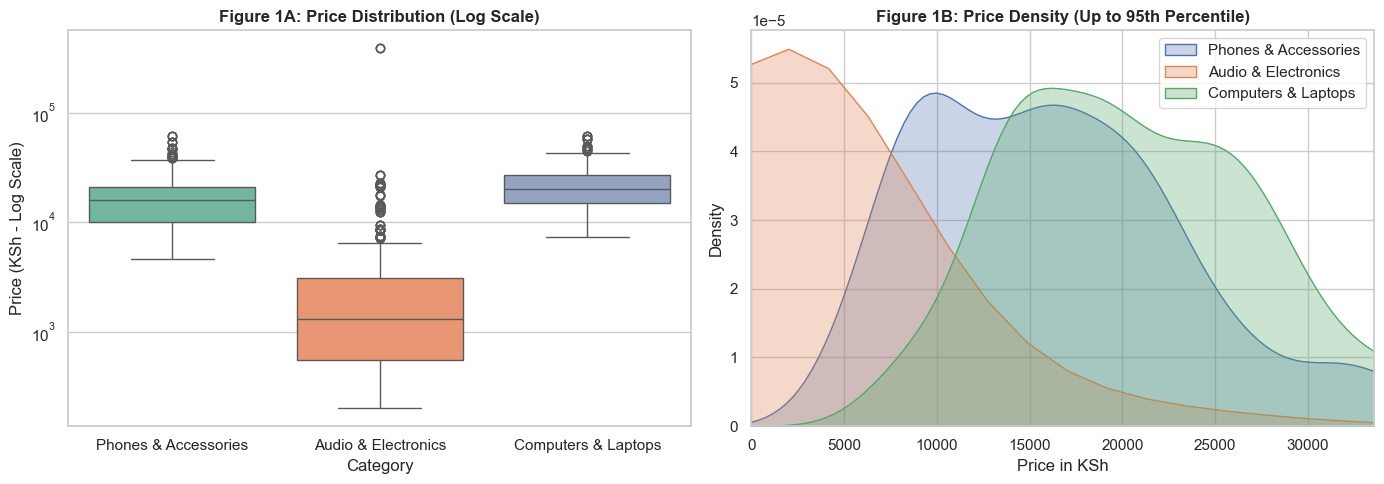

In [2]:
plt.close('all') # Clear canvas

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Boxplot (Log scale to show outliers clearly)
sns.boxplot(data=df, x="category", y="price", hue="category", palette="Set2", ax=axes[0], legend=False)
axes[0].set_yscale("log")
axes[0].set_title("Figure 1A: Price Distribution (Log Scale)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Price (KSh - Log Scale)")
axes[0].set_xlabel("Category")

# 2. Price Density Curve
for cat in df["category"].unique():
    subset = df[df["category"] == cat]
    sns.kdeplot(subset["price"], ax=axes[1], label=cat, fill=True, alpha=0.3)

axes[1].set_xlim(0, df["price"].quantile(0.95)) # Focus on the typical range
axes[1].set_title("Figure 1B: Price Density (Up to 95th Percentile)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Price in KSh")
axes[1].set_ylabel("Density")
axes[1].legend()

plt.tight_layout()
plt.show()

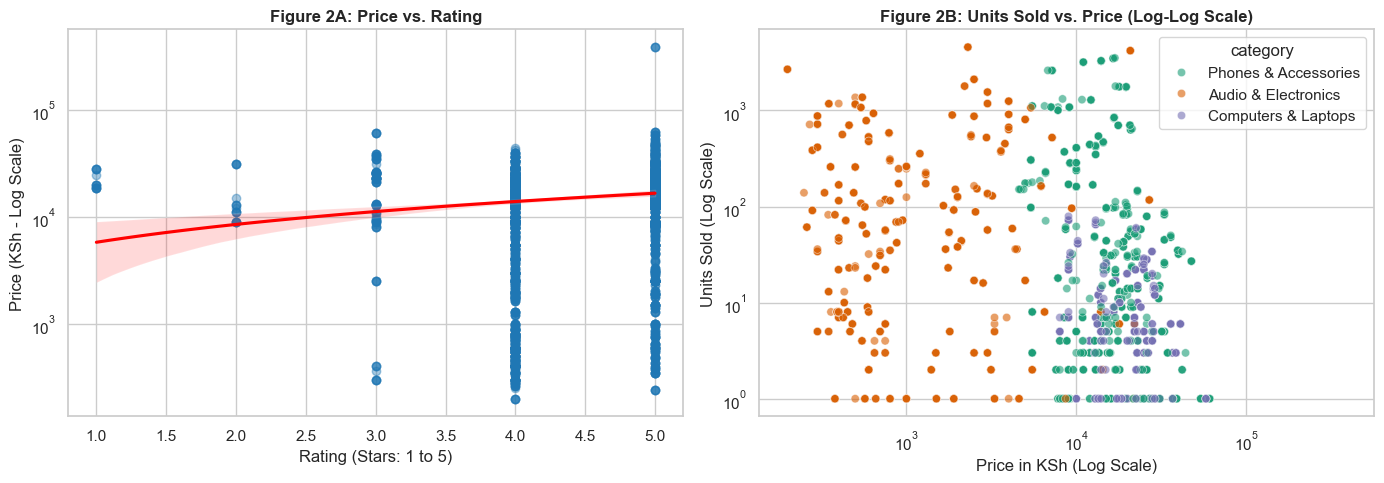

In [3]:
plt.close('all')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Price vs. Rating
rated_items = df[df["rating"] > 0]
sns.regplot(data=rated_items, x="rating", y="price", scatter_kws={"alpha":0.4, "color":"#1f77b4"}, line_kws={"color":"red"}, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Figure 2A: Price vs. Rating", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Rating (Stars: 1 to 5)")
axes[0].set_ylabel("Price (KSh - Log Scale)")

# 2. Sales vs. Price
sns.scatterplot(data=df, x="price", y="units_sold", hue="category", alpha=0.6, palette="Dark2", ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_title("Figure 2B: Units Sold vs. Price (Log-Log Scale)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Price in KSh (Log Scale)")
axes[1].set_ylabel("Units Sold (Log Scale)")

plt.tight_layout()
plt.show()

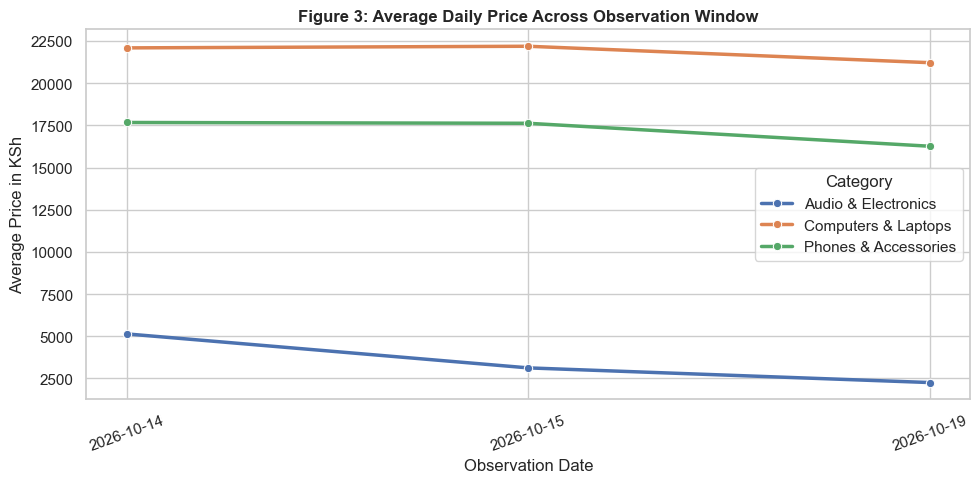

In [4]:
plt.close('all')

# Group by day and category
daily_trend = df.groupby(["scrape_date", "category"])["price"].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=daily_trend, x="scrape_date", y="price", hue="category", marker="o", linewidth=2.5)
plt.title("Figure 3: Average Daily Price Across Observation Window", fontsize=12, fontweight="bold")
plt.xlabel("Observation Date")
plt.ylabel("Average Price in KSh")
plt.xticks(rotation=20)
plt.legend(title="Category")
plt.tight_layout()
plt.show()

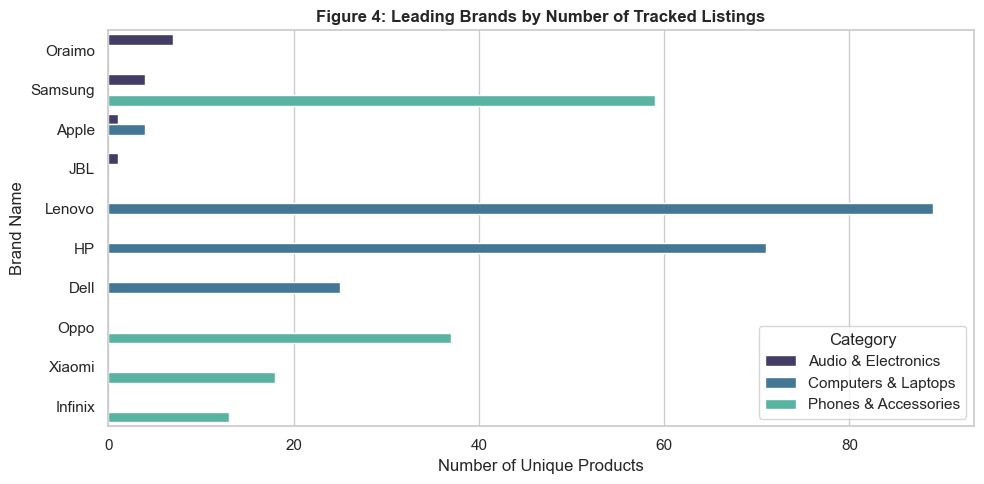

In [5]:
plt.close('all')

# Filter to known brands only
branded_data = df[df["brand"] != "Other / Unbranded"]
top_brands = branded_data.groupby(["category", "brand"])["product_id"].nunique().reset_index()
top_brands.rename(columns={"product_id": "total_products"}, inplace=True)

# Top 4 brands per category
top_per_cat = top_brands.sort_values(["category", "total_products"], ascending=[True, False]).groupby("category").head(4)

plt.figure(figsize=(10, 5))
sns.barplot(data=top_per_cat, x="total_products", y="brand", hue="category", palette="mako")
plt.title("Figure 4: Leading Brands by Number of Tracked Listings", fontsize=12, fontweight="bold")
plt.xlabel("Number of Unique Products")
plt.ylabel("Brand Name")
plt.legend(title="Category", loc="lower right")
plt.tight_layout()
plt.show()

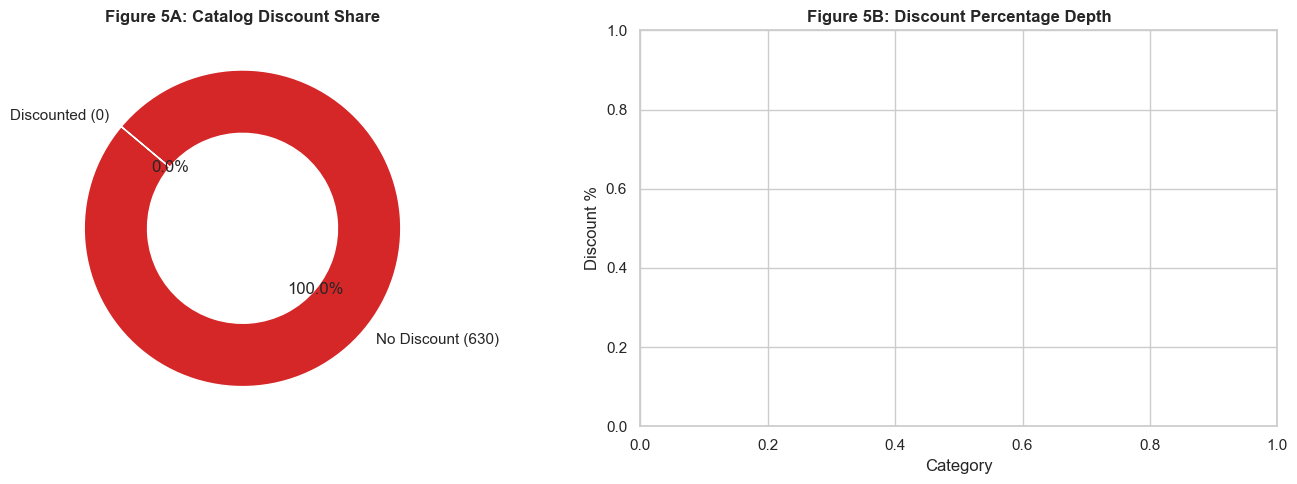

In [6]:
plt.close('all')

# Get latest record per product
latest = df.sort_values("scraped_at").groupby("product_id").last().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Share of discounted products
disc_count = (latest["discount_percent"] > 0).sum()
no_disc = len(latest) - disc_count
axes[0].pie([disc_count, no_disc], labels=[f"Discounted ({disc_count})", f"No Discount ({no_disc})"], 
            autopct="%1.1f%%", colors=["#2ca02c", "#d62728"], startangle=140, wedgeprops=dict(width=0.4))
axes[0].set_title("Figure 5A: Catalog Discount Share", fontsize=12, fontweight="bold")

# 2. Size of active discounts
active_discounts = latest[latest["discount_percent"] > 0]
sns.boxplot(data=active_discounts, x="category", y="discount_percent", hue="category", palette="pastel", ax=axes[1], legend=False)
axes[1].set_title("Figure 5B: Discount Percentage Depth", fontsize=12, fontweight="bold")
axes[1].set_ylabel("Discount %")
axes[1].set_xlabel("Category")

plt.tight_layout()
plt.show()

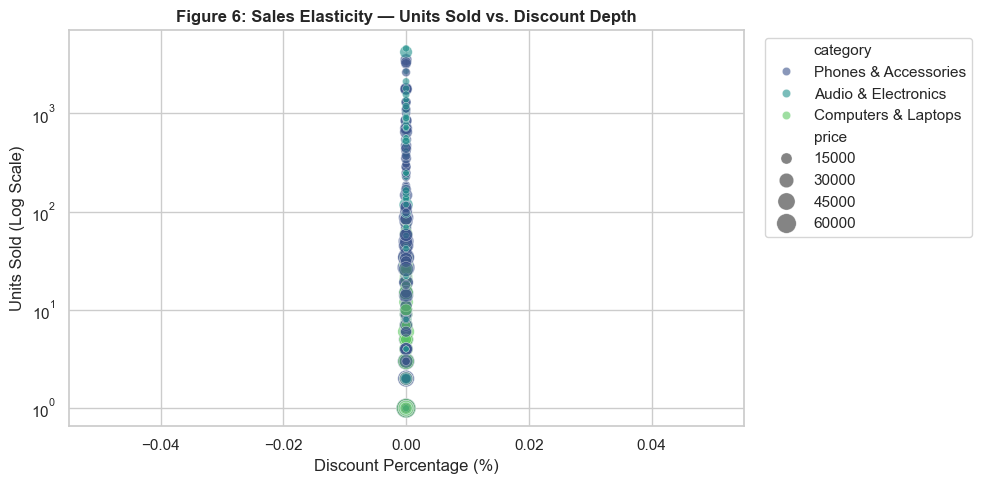

In [7]:
plt.close('all')

# Our Question: Do higher discounts actually mean more units sold?
valid_sales = latest[latest["units_sold"] > 0]

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=valid_sales, 
    x="discount_percent", 
    y="units_sold", 
    hue="category", 
    size="price", 
    sizes=(20, 200),
    alpha=0.6, 
    palette="viridis"
)
plt.yscale("log")
plt.title("Figure 6: Sales Elasticity — Units Sold vs. Discount Depth", fontsize=12, fontweight="bold")
plt.xlabel("Discount Percentage (%)")
plt.ylabel("Units Sold (Log Scale)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

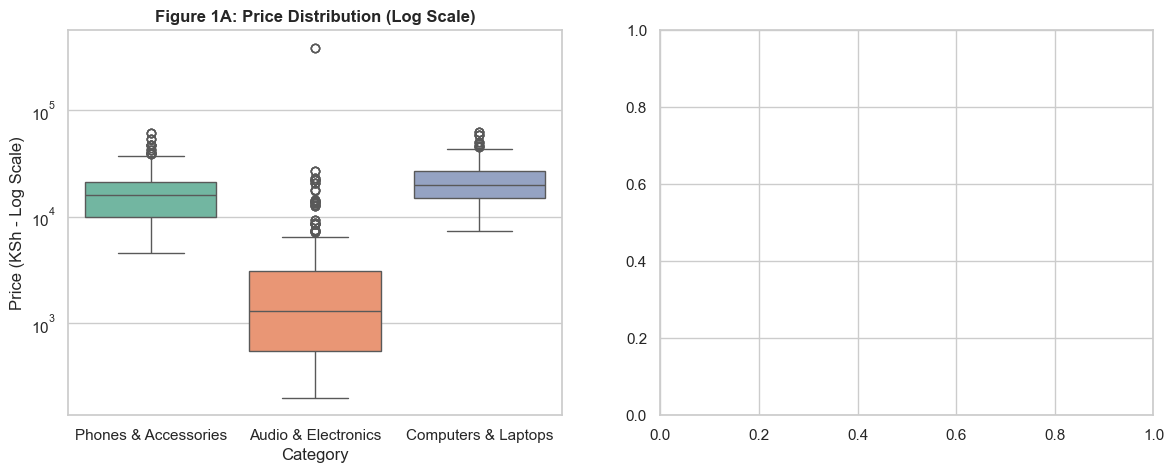

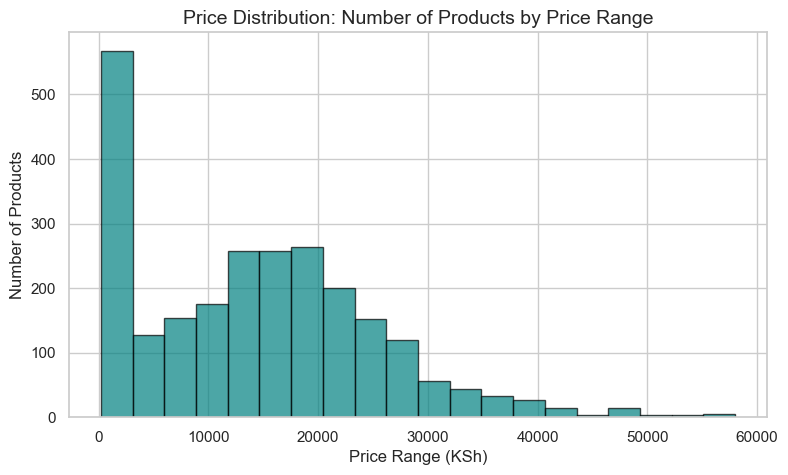

In [11]:
plt.close('all') # Clear canvas

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Boxplot (Log scale to show outliers clearly)
sns.boxplot(data=df, x="category", y="price", hue="category", palette="Set2", ax=axes[0], legend=False)
axes[0].set_yscale("log")
axes[0].set_title("Figure 1A: Price Distribution (Log Scale)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Price (KSh - Log Scale)")
axes[0].set_xlabel("Category")

plt.figure(figsize=(9, 5))

# Filter out extreme outliers above 60,000 KSh so the bars look neat
typical_items = df[df["price"] < 60000]

# Standard histogram with 20 bins (baskets)
plt.hist(typical_items["price"], bins=20, color="teal", edgecolor="black", alpha=0.7)

plt.title("Price Distribution: Number of Products by Price Range", fontsize=14)
plt.xlabel("Price Range (KSh)")
plt.ylabel("Number of Products")
plt.show()